In [1]:
import sys
from pathlib import Path

# make `import utils` work no matter where the kernel starts
HERE = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "utils" / "graph_view.py").is_file())
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

from utils import (
    FIG_DIR,
    FORMATED_DIR,
    MAX_NODES,
    SEED,
    draw_dataset,
    draw_grid,
    graph_stats,
    load_dataset,
    project,
)

DATASET = "college-msg"   # any file stem inside benchmark/dataset/formated/
MAX_NODES = 4090           # vertices kept in the sample
SEED = 42                 # deterministic sampling and layout

print("formated :", FORMATED_DIR)
print("available:", sorted(p.stem for p in FORMATED_DIR.glob("*.txt")))

formated : /workspaces/top-k-husm-mg/benchmark/dataset/formated
available: ['bn-fly-drosophila', 'college-msg', 'dblp-multigraph', 'email-eu-core-temporal', 'sx-askubuntu', 'sx-mathoverflow', 'sx-superuser']


In [2]:
G = load_dataset(DATASET)
S = project(G)
stats = graph_stats(G)

print(f"{DATASET}.txt")
print(f"  vertices            {stats['nodes']:,}")
print(f"  edges               {stats['edges']:,}")
print(f"  vertex pairs        {stats['pairs']:,}")
print(f"  edge types          {stats['types']:,}")
print(f"  max degree          {stats['max_degree']:,} (vertex {stats['max_degree_node']})")
print(f"  max parallel edges  {stats['max_parallel']:,}")
print(f"  components          {stats['components']:,}")

college-msg.txt
  vertices            1,899
  edges               36,821
  vertex pairs        13,838
  edge types          10
  max degree          722 (vertex 8)
  max parallel edges  16
  components          4


## 2. Draw one dataset

`draw_dataset()` samples the 2-hop ego-network of the highest-degree vertex, keeps
the largest connected component and renders it as a spring layout (node size and
colour = degree, edge width = multiplicity). The figure is written to
`benchmark/visualize/out/<dataset>.png`.

college-msg: 1,899 vertices | 36,821 edges | 13,838 pairs | 10 edge types | max degree 722 (vertex 8) | max parallel 16 | components 4
saved: /workspaces/top-k-husm-mg/benchmark/visualize/out/college-msg.png


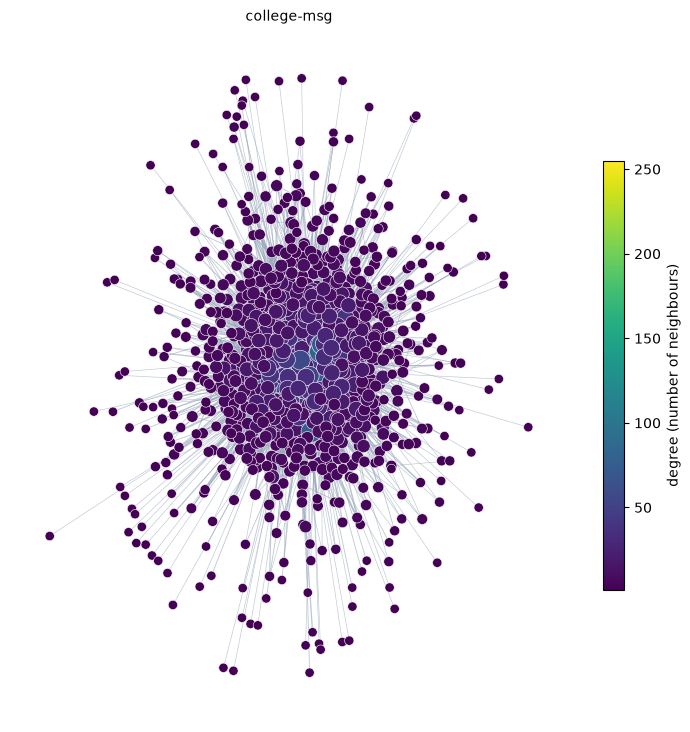

In [3]:
draw_dataset(DATASET, max_nodes=MAX_NODES, seed=SEED);

saved: /workspaces/top-k-husm-mg/benchmark/visualize/out/grid.png


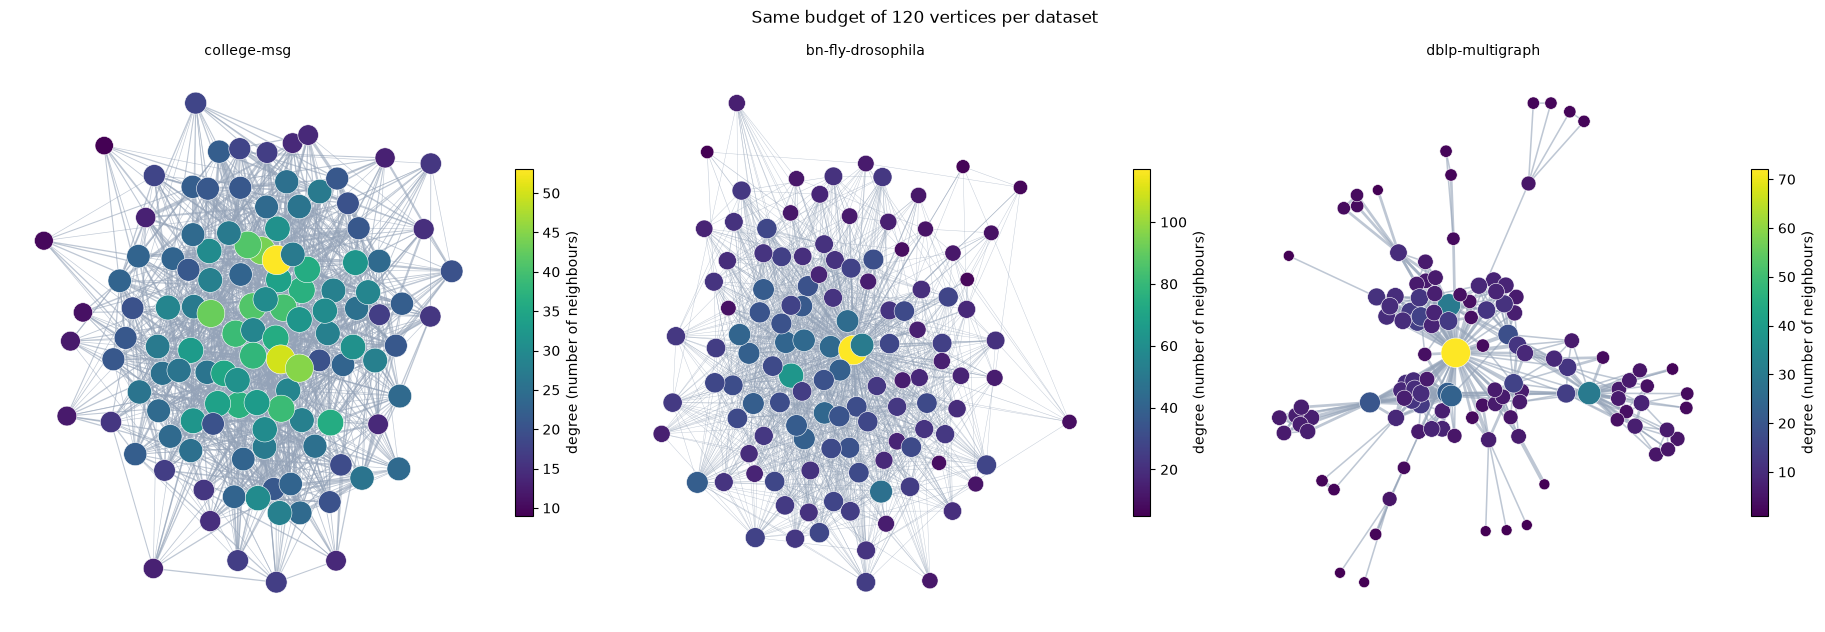

In [4]:
DATASETS = ["college-msg", "bn-fly-drosophila", "dblp-multigraph"]
draw_grid(DATASETS, max_nodes=120, save=FIG_DIR / "grid.png");